# OLS Formulae for Linear Regression

In [51]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
import numpy as np

diabetes = load_diabetes()
x = diabetes.data
y = diabetes.target

from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

LR = LinearRegression()
LR.fit(x_train, y_train)
y_pred = LR.predict(x_test)

print(f'''R2Score : {r2_score(y_test, y_pred) * 100} %''')

print(f'''Slop : {LR.coef_}''')
print(f'''Intercept : {LR.intercept_}''')

R2Score : 45.260276297191936 %
Slop : [  37.90402135 -241.96436231  542.42875852  347.70384391 -931.48884588
  518.06227698  163.41998299  275.31790158  736.1988589    48.67065743]
Intercept : 151.34560453985995


### From scratch implementation of SGD

In [52]:
class SGDClass:
  def __init__(self , learning_rate , eipose):
    self.lr = learning_rate
    self.eipose = eipose #No. of iterations
    self.coef = 0 # Beta 1,2,3 Its a 1D Array that stores all the values
    self.intersept = 1 #Beta zero it is

  def fit(self , X, Y):
    self.intersept = 0
    self.coef = np.ones(X.shape[1]) # Initialize the coefficients with 1 respectively number of columns

    # print(X.shape)

    for i in range(self.eipose):
      for j in range(X.shape[0]):
        idx = np.random.randint(0, X.shape[0])
        
        y_pred = np.dot(X[idx], self.coef) + self.intersept

        intercept_derivative = -2 * (Y[idx] - y_pred)
        coeff_derivative = -2 * (X[idx] * (Y[idx] - y_pred))

        self.intersept = self.intersept - (self.lr * intercept_derivative)
        self.coef = self.coef - (self.lr * coeff_derivative) 

  def predict(self , X):
    return np.dot(X, self.coef) + self.intersept

SGDown = SGDClass(learning_rate=0.1, eipose=18) 
SGDown.fit(x_train, y_train)
y_pred_SGD = SGDown.predict(x_test)

print(f'''Slop : {SGDown.coef}''')
print(f'''Intercept : {SGDown.intersept}''')
print(f'''R2Score : {r2_score(y_test, y_pred_SGD) * 100} %''')


Slop : [  70.94608541 -212.31043939  505.93007191  373.82034284  -90.57228402
 -141.4388677  -226.14841489  146.54344018  410.20148643  120.9589589 ]
Intercept : 155.25440111878606
R2Score : 45.05687396936471 %


### skLearn Stochastic GD Class

In [53]:
from sklearn.linear_model import SGDRegressor

SGDReg = SGDRegressor(max_iter=100, learning_rate='constant', eta0=0.1)
SGDReg.fit(x_train, y_train)
y_pred_SGDReg = SGDReg.predict(x_test)  
print(f'''R2Score : {r2_score(y_test, y_pred_SGDReg) * 100} %''')


R2Score : 42.29082088587123 %


## Implementation on Housing Dataset

In [54]:
import pandas
import numpy as np
from sklearn.preprocessing import StandardScaler , OneHotEncoder ,OrdinalEncoder
from sklearn.pipeline import Pipeline
import seaborn as sns

df = pandas.read_csv('/Users/abheetsharma/Downloads/csvDataset/Housing.csv')

df.sample(14)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
12,9310000,6550,4,2,2,yes,no,no,no,yes,1,yes,semi-furnished
158,5495000,7980,3,1,1,yes,no,no,no,no,2,no,semi-furnished
44,7560000,6000,4,2,4,yes,no,no,no,yes,1,no,furnished
377,3640000,2850,3,2,2,no,no,yes,no,no,0,yes,unfurnished
18,8890000,4600,3,2,2,yes,yes,no,no,yes,2,no,furnished
261,4473000,3510,3,1,2,yes,no,no,no,no,0,no,semi-furnished
152,5565000,5400,5,1,2,yes,yes,yes,no,yes,0,yes,furnished
212,4893000,3420,4,2,2,yes,no,yes,no,yes,2,no,semi-furnished
96,6300000,9000,3,1,1,yes,no,yes,no,no,1,yes,furnished
408,3430000,4000,2,1,1,yes,no,no,no,no,0,no,unfurnished


In [55]:
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(missing_values=np.nan, strategy='mean')
df['price'] = imputer.fit_transform(df[['price']])
df['area'] = imputer.fit_transform(df[['area']])

<Axes: xlabel='bedrooms', ylabel='Count'>

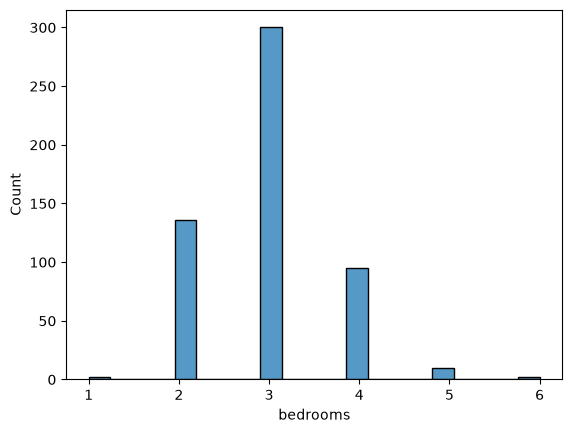

In [56]:
#Plot a histogram on the price column
sns.histplot(df['bedrooms'])

In [57]:
#Applying Log Transformer on the Price Values
df['price'] = np.log(df['price'])
df['area'] = np.log(df['area'])

#Creating a Pipeline with dense output for OneHotEncoder
ss_pipeline_1 = Pipeline([('ss', StandardScaler())])
ohe_pipeline_2 = Pipeline([('ohe', OneHotEncoder(drop='first', sparse_output=False))])
oe_pipeline_3 = Pipeline([
    ('oe', OrdinalEncoder(categories=[['unfurnished', 'semi-furnished', 'furnished']]))
])

#Transforming and Saving the Values
df['price'] = ss_pipeline_1.fit_transform(df[['price']])
df['area'] = ss_pipeline_1.fit_transform(df[['area']])
df['mainroad'] = ohe_pipeline_2.fit_transform(df[['mainroad']])
df['airconditioning'] = ohe_pipeline_2.fit_transform(df[['airconditioning']])
df['prefarea'] = ohe_pipeline_2.fit_transform(df[['prefarea']])
df['hotwaterheating'] = ohe_pipeline_2.fit_transform(df[['hotwaterheating']])
df['guestroom'] = ohe_pipeline_2.fit_transform(df[['guestroom']])
df['basement'] = ohe_pipeline_2.fit_transform(df[['basement']])
df['furnishingstatus'] = oe_pipeline_3.fit_transform(df[['furnishingstatus']])

df.sample(14)

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
43,1.478508,0.585491,4,2,4,1.0,0.0,0.0,0.0,0.0,2,0.0,1.0
217,0.224220,0.922846,3,1,2,1.0,0.0,0.0,0.0,1.0,2,1.0,2.0
432,-0.808418,0.610497,3,1,1,1.0,1.0,1.0,0.0,0.0,0,0.0,2.0
484,-1.175730,-1.123158,2,1,1,0.0,0.0,0.0,0.0,0.0,0,0.0,0.0
372,-0.536525,-1.010010,3,1,2,0.0,0.0,1.0,0.0,0.0,0,0.0,1.0
469,-1.047637,-0.082243,2,1,1,1.0,0.0,0.0,0.0,0.0,0,0.0,2.0
289,-0.151663,0.521865,2,1,1,1.0,1.0,1.0,0.0,0.0,2,0.0,1.0
340,-0.385675,0.273736,5,2,2,1.0,0.0,0.0,0.0,0.0,0,0.0,1.0
348,-0.410237,-1.033831,2,2,1,0.0,0.0,1.0,0.0,0.0,0,0.0,1.0
7,2.221477,3.081613,5,3,2,1.0,0.0,0.0,0.0,0.0,0,0.0,0.0


In [58]:
#Train a LinearRegression Model on the df dataset price as target
x = df.drop('price', axis=1)
y = df['price']

from sklearn.model_selection import train_test_split
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import r2_score

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
SDG = SGDRegressor(max_iter=40 , learning_rate='constant' , eta0=0.01)
SDG.fit(x_train, y_train)
y_pred = SDG.predict(x_test)

print(f'''R2Score : {r2_score(y_test, y_pred) * 100} %''')

R2Score : 66.04327005167549 %
